<a href="https://colab.research.google.com/github/anupbagale/segmentation-colormap/blob/main/notebooks/01_colormaps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colour maps

A colour map turns numbers into colours. Matplotlib uses one every time it shows a single-channel
array with `imshow`. This notebook looks at the two kinds of colour map, builds one from a list of
RGB values, and covers the mistakes that make label images show the wrong colours.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from skimage import data

## Continuous colour maps

For measurements such as brightness or temperature, nearby values should get similar colours.
Matplotlib has many of these built in. `gray` and `viridis` are two of them.

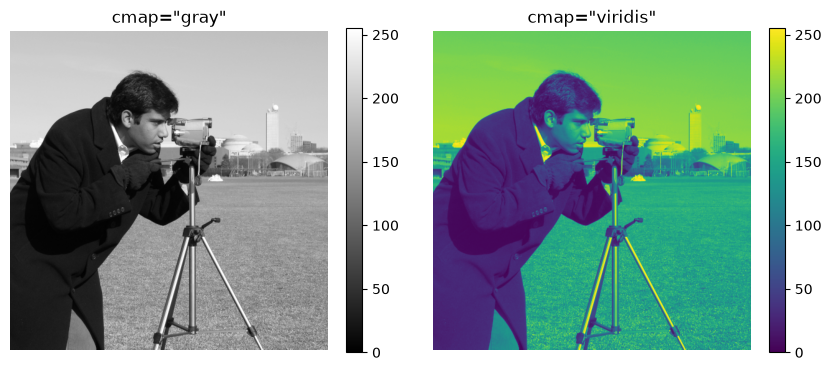

In [2]:
image = data.camera()

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, cmap in zip(ax, ["gray", "viridis"]):
    im = a.imshow(image, cmap=cmap)
    a.set_title(f'cmap="{cmap}"')
    a.axis("off")
    fig.colorbar(im, ax=a, fraction=0.046)
plt.show()

## A colour map from your own colours

For labels (1 = cortex, 2 = white matter, and so on) the numbers are categories, not amounts, so
each label should get its own distinct colour. `ListedColormap` takes a list of colours. Matplotlib
expects RGB values between 0 and 1, so values written as 0 to 255 are divided by 255 first.

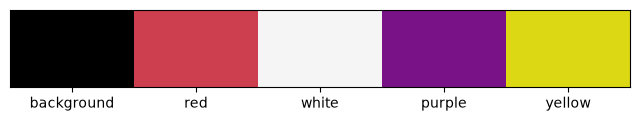

In [3]:
rgb = np.array([
    [0, 0, 0],          # 0 background
    [205, 62, 78],      # 1 red
    [245, 245, 245],    # 2 white
    [120, 18, 134],     # 3 purple
    [220, 216, 20],     # 4 yellow
]) / 255
names = ["background", "red", "white", "purple", "yellow"]
cmap = ListedColormap(rgb)

fig, ax = plt.subplots(figsize=(8, 1))
ax.imshow(np.arange(len(rgb))[None, :], cmap=cmap, aspect="auto")
ax.set_xticks(range(len(rgb)), names)
ax.set_yticks([])
plt.show()

## A small label image

Here is a label image with four regions on a background. Each pixel holds one label from 0 to 4.

In [4]:
yy, xx = np.mgrid[0:120, 0:160]
labels = np.zeros((120, 160), dtype=int)
labels[(xx - 50) ** 2 + (yy - 60) ** 2 < 35 ** 2] = 1
labels[(xx - 50) ** 2 + (yy - 60) ** 2 < 18 ** 2] = 2
labels[(xx > 95) & (xx < 145) & (yy > 20) & (yy < 55)] = 3
labels[(xx > 95) & (xx < 145) & (yy > 70) & (yy < 105)] = 4
print("labels in the image:", np.unique(labels))

labels in the image: [0 1 2 3 4]


## The colours can shift

`imshow` does not look up label 3 as "colour number 3". It first scales the data to the range
0 to 1, using the smallest and largest value **in this image**, and then picks a colour. When every
label is present that works out. When one is missing, the scaling changes and labels get the wrong
colour.

Below, label 4 (yellow) is removed. Label 3 is now the largest value, so it is scaled to 1 and drawn
in yellow, the last colour of the map, instead of purple.

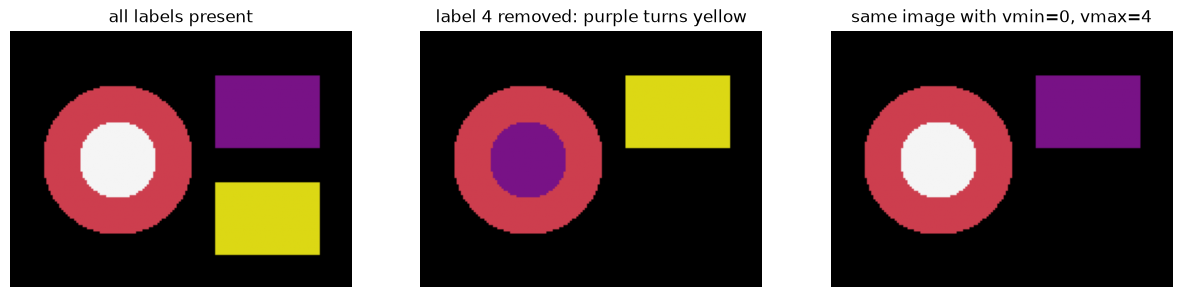

In [5]:
no_yellow = np.where(labels == 4, 0, labels)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(labels, cmap=cmap)
ax[0].set_title("all labels present")
ax[1].imshow(no_yellow, cmap=cmap)
ax[1].set_title("label 4 removed: purple turns yellow")
ax[2].imshow(no_yellow, cmap=cmap, vmin=0, vmax=len(rgb) - 1)
ax[2].set_title("same image with vmin=0, vmax=4")
for a in ax:
    a.axis("off")
plt.show()

Fixing the range with `vmin` and `vmax` (or with a `BoundaryNorm`, used below) makes every label
map to the same colour no matter which labels the image contains.

## Transparent background with `set_bad`

To draw labels on top of a photo, the background should be see-through. `set_bad` sets the colour
used for "bad" values, which are NaN values and masked entries of a masked array. Masking label 0
and making bad values fully transparent lets the photo show through.

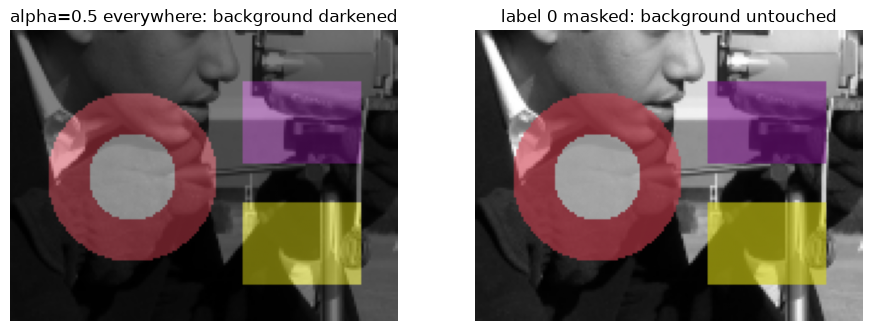

In [6]:
photo = data.camera()[150:270, 160:320]          # 120 x 160, same size as the labels

overlay_cmap = ListedColormap(rgb)
overlay_cmap.set_bad(alpha=0)                     # masked pixels: fully transparent
masked = np.ma.masked_equal(labels, 0)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].imshow(photo, cmap="gray")
ax[0].imshow(labels, cmap=cmap, vmin=0, vmax=4, alpha=0.5)
ax[0].set_title("alpha=0.5 everywhere: background darkened")
ax[1].imshow(photo, cmap="gray")
ax[1].imshow(masked, cmap=overlay_cmap, vmin=0, vmax=4, alpha=0.6)
ax[1].set_title("label 0 masked: background untouched")
for a in ax:
    a.axis("off")
plt.show()

On the left, the black background colour is blended over the whole photo and darkens it. On the
right, only the labelled regions are coloured.

## A colour bar with names

A `BoundaryNorm` with boundaries halfway between the labels gives each label its own block in the
colour bar, and the ticks can then carry the label names.

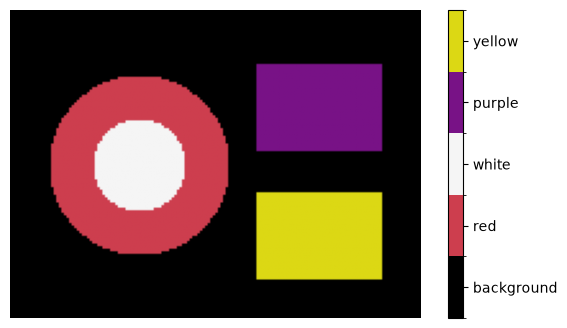

In [7]:
bounds = np.arange(len(rgb) + 1) - 0.5           # -0.5, 0.5, 1.5, ... 4.5
norm = BoundaryNorm(bounds, len(rgb))

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(labels, cmap=cmap, norm=norm)
ax.axis("off")
cbar = fig.colorbar(im, ax=ax, ticks=range(len(rgb)))
cbar.ax.set_yticklabels(names)
plt.show()

Notebook 02 uses the same ideas on a real brain MRI segmentation with 46 labels, whose numbers
are not 0, 1, 2, ... but values such as 2, 41 and 255.